# Walmart Weekly Sales: Exploratory Time Series Analysis

This notebook comes before the modelling in `main.py`. It covers:

1. **Data audit**: schema, coverage, missing values, store heterogeneity
2. **Temporal structure**: trend, annual seasonality, holiday spikes
3. **Exogenous drivers**: `CPI`, `Fuel_Price`, `Unemployment`, `Temperature`, `Holiday_Flag`
4. **Decomposition & stationarity**: STL, ADF tests, ACF/PACF (these set SARIMA's `d`, `D`, `p`, `q`)
5. **Feature signal**: how much the lags `t-1`, `t-4`, `t-52` carry for XGBoost

> Data is pulled with `kagglehub` (`mikhail1681/walmart-sales`). Set the environment variable
> `WALMART_DATA_PATH` to point at a local `Walmart.csv` to skip the download.

In [1]:
import os, sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.data_prep import prepare_data, TARGET
from src.features import create_features
from src.utils import run_adf_test, set_plot_style

%matplotlib inline
set_plot_style()
sns.set_palette("deep")
MILLIONS = FuncFormatter(lambda x, _: f"${x/1e6:,.0f}M")
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

## 1. Load & audit the data

In [2]:
data = prepare_data(os.environ.get("WALMART_DATA_PATH"), test_size=0.2)
df, weekly = data.store_df, data.weekly
print(f"Rows: {len(df):,} | Stores: {df.Store.nunique()} | Weeks: {df.Date.nunique()}")
print(f"Coverage: {df.Date.min().date()} -> {df.Date.max().date()}")
print(f"Train: {data.train.index.min().date()} -> {data.train.index.max().date()} ({len(data.train)} wks)")
print(f"Test : {data.test.index.min().date()} -> {data.test.index.max().date()} ({len(data.test)} wks)")
df.head()

Rows: 6,435 | Stores: 45 | Weeks: 143
Coverage: 2010-02-05 -> 2012-10-26
Train: 2010-02-05 -> 2012-04-06 (114 wks)
Test : 2012-04-13 -> 2012-10-26 (29 wks)


,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,"1,643,690.90",0,42.31,2.57,211.10,8.11
1,1,2010-02-12,"1,641,957.44",1,38.51,2.55,211.24,8.11
2,1,2010-02-19,"1,611,968.17",0,39.93,2.51,211.29,8.11
3,1,2010-02-26,"1,409,727.59",0,46.63,2.56,211.32,8.11
4,1,2010-03-05,"1,554,806.68",0,46.50,2.62,211.35,8.11


In [3]:
audit = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "n_unique": df.nunique(),
})
display(audit)
display(df.describe().T)

,dtype,missing,n_unique
Store,int64,0,45
Date,datetime64[us],0,143
Weekly_Sales,float64,0,6435
Holiday_Flag,int64,0,2
Temperature,float64,0,3528
Fuel_Price,float64,0,892
CPI,float64,0,2145
Unemployment,float64,0,349


,count,mean,min,25%,50%,75%,max,std
Store,"6,435.00",23.00,1.00,12.00,23.00,34.00,45.00,12.99
Date,6435,2011-06-17 00:00:00,2010-02-05 00:00:00,2010-10-08 00:00:00,2011-06-17 00:00:00,2012-02-24 00:00:00,2012-10-26 00:00:00,NaN
Weekly_Sales,"6,435.00","1,046,964.88","209,986.25","553,350.10","960,746.04","1,420,158.66","3,818,686.45","564,366.62"
Holiday_Flag,"6,435.00",0.07,0.00,0.00,0.00,0.00,1.00,0.26
Temperature,"6,435.00",60.66,-2.06,47.46,62.67,74.94,100.14,18.44
Fuel_Price,"6,435.00",3.36,2.47,2.93,3.44,3.73,4.47,0.46
CPI,"6,435.00",171.58,126.06,131.74,182.62,212.74,227.23,39.36
Unemployment,"6,435.00",8.00,3.88,6.89,7.87,8.62,14.31,1.88


In [4]:
# Panel completeness: every store should report every week.
coverage = df.groupby("Store")["Date"].nunique()
print("Weeks per store:", coverage.min(), "to", coverage.max())
print("Balanced panel:", coverage.nunique() == 1)

Weeks per store: 143 to 143
Balanced panel: True


### Store heterogeneity
Store sizes vary a lot. A single global model has to cope with that spread, which is why XGBoost
takes `Store` as a categorical feature plus per-store lags.

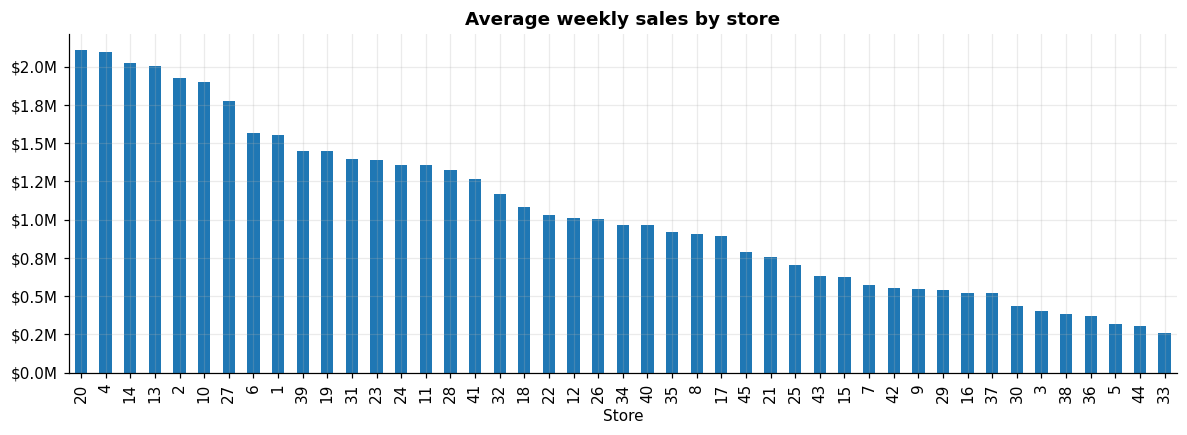

Largest / smallest store ratio: 8.1x


In [5]:
store_tot = df.groupby("Store")[TARGET].mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(13, 4))
store_tot.plot.bar(ax=ax, color="#1f77b4")
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1e6:,.1f}M"))
ax.set_title("Average weekly sales by store"); ax.set_xlabel("Store")
plt.show()
print(f"Largest / smallest store ratio: {store_tot.max() / store_tot.min():.1f}x")

## 2. Chain-level temporal structure

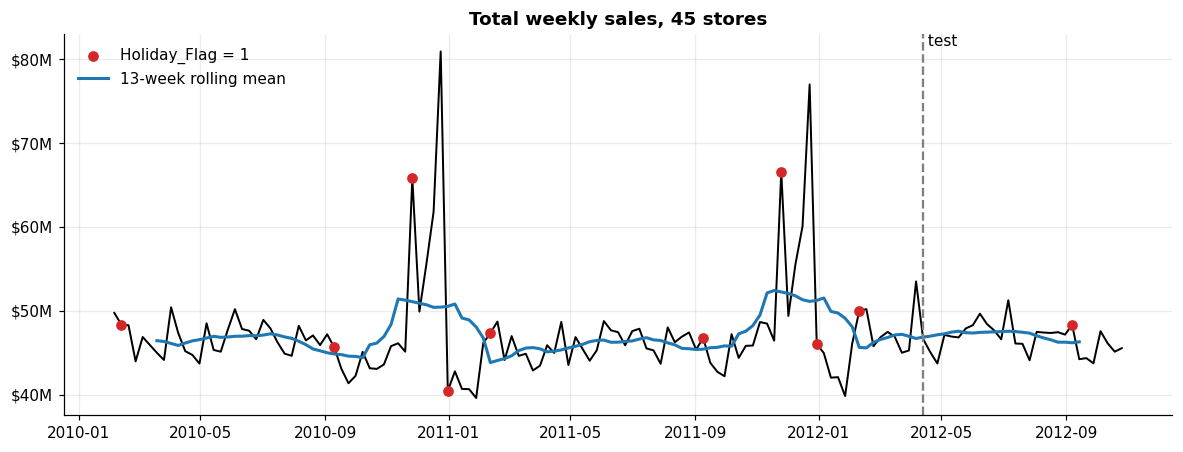

In [6]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(weekly.index, weekly[TARGET], color="black", lw=1.3)
hol = weekly[weekly.Holiday_Flag == 1]
ax.scatter(hol.index, hol[TARGET], color="#d62728", zorder=3, label="Holiday_Flag = 1")
ax.plot(weekly.index, weekly[TARGET].rolling(13, center=True).mean(), color="#1f77b4", lw=2, label="13-week rolling mean")
ax.axvline(data.split_date, ls="--", color="grey"); ax.text(data.split_date, ax.get_ylim()[1], " test", va="top")
ax.yaxis.set_major_formatter(MILLIONS); ax.legend(frameon=False); ax.set_title("Total weekly sales, 45 stores")
plt.show()

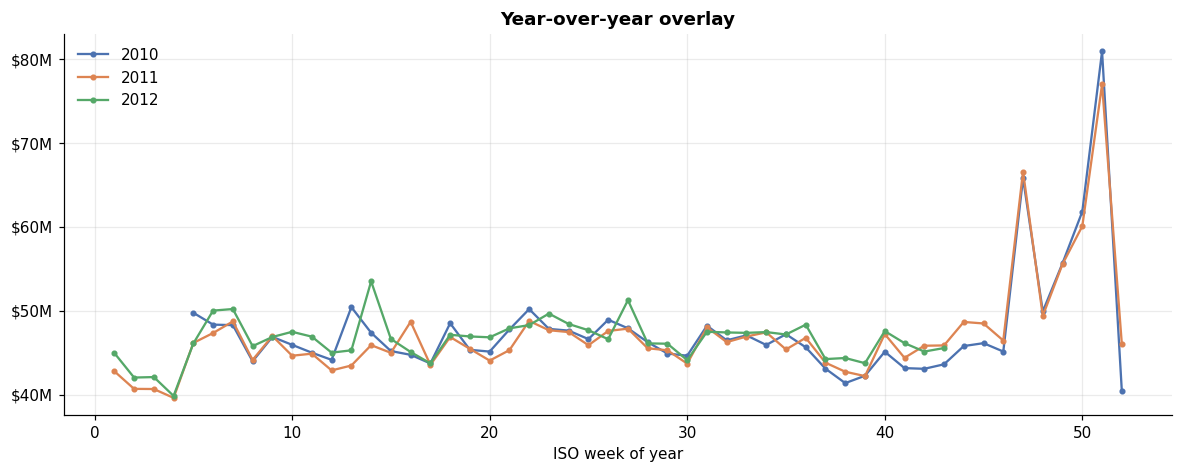

In [7]:
# Year-over-year overlay by ISO week: repeating peaks mean annual seasonality (m = 52).
yoy = weekly.assign(Year=weekly.index.year, Week=weekly.index.isocalendar().week.values)
fig, ax = plt.subplots(figsize=(13, 4.5))
for yr, g in yoy.groupby("Year"):
    ax.plot(g.Week, g[TARGET], marker="o", ms=3, label=str(yr))
ax.yaxis.set_major_formatter(MILLIONS); ax.set_xlabel("ISO week of year")
ax.set_title("Year-over-year overlay"); ax.legend(frameon=False)
plt.show()

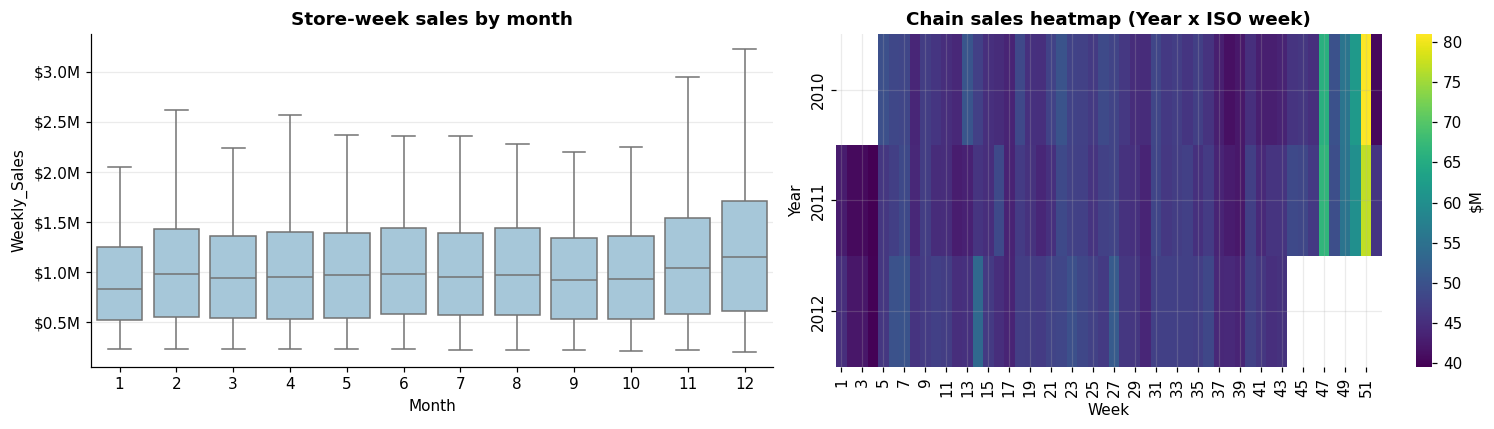

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
m = df.assign(Month=df.Date.dt.month)
sns.boxplot(data=m, x="Month", y=TARGET, ax=axes[0], color="#9ecae1", showfliers=False)
axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, _: f"${x/1e6:,.1f}M")); axes[0].set_title("Store-week sales by month")
pivot = yoy.pivot_table(index="Year", columns="Week", values=TARGET)
sns.heatmap(pivot / 1e6, cmap="viridis", ax=axes[1], cbar_kws={"label": "$M"})
axes[1].set_title("Chain sales heatmap (Year x ISO week)")
plt.tight_layout(); plt.show()

### Holiday effect

In [9]:
hol_stats = df.groupby("Holiday_Flag")[TARGET].agg(["mean", "median", "count"])
display(hol_stats)
uplift = hol_stats.loc[1, "mean"] / hol_stats.loc[0, "mean"] - 1
print(f"Mean uplift on flagged holiday weeks: {uplift:+.1%}")

# The four flagged events are not equal; name them by month.
names = {2: "Super Bowl", 9: "Labor Day", 11: "Thanksgiving", 12: "Christmas"}
hw = weekly[weekly.Holiday_Flag == 1].copy()
hw["Event"] = hw.index.month.map(names)
base = weekly.loc[weekly.Holiday_Flag == 0, TARGET].median()
display((hw.groupby("Event")[TARGET].mean() / base - 1).rename("uplift_vs_median_week").to_frame().style.format("{:+.1%}"))

,mean,median,count
Holiday_Flag,,,
0,"1,041,256.38","956,211.20",5985
1,"1,122,887.89","1,018,538.04",450


Mean uplift on flagged holiday weeks: +7.8%


,uplift_vs_median_week
Event,
Christmas,-6.3%
Labor Day,+1.7%
Super Bowl,+5.3%
Thanksgiving,+43.5%


Walmart's `Holiday_Flag` marks the week that *contains* each holiday. For Christmas that is the
week ending in late December, **after** most gift shopping is done. The real retail peak is usually one
or two weeks earlier. That is why the Prophet holiday calendar in `src/models.py` gives Christmas a
`lower_window=-14`.

## 3. Exogenous drivers

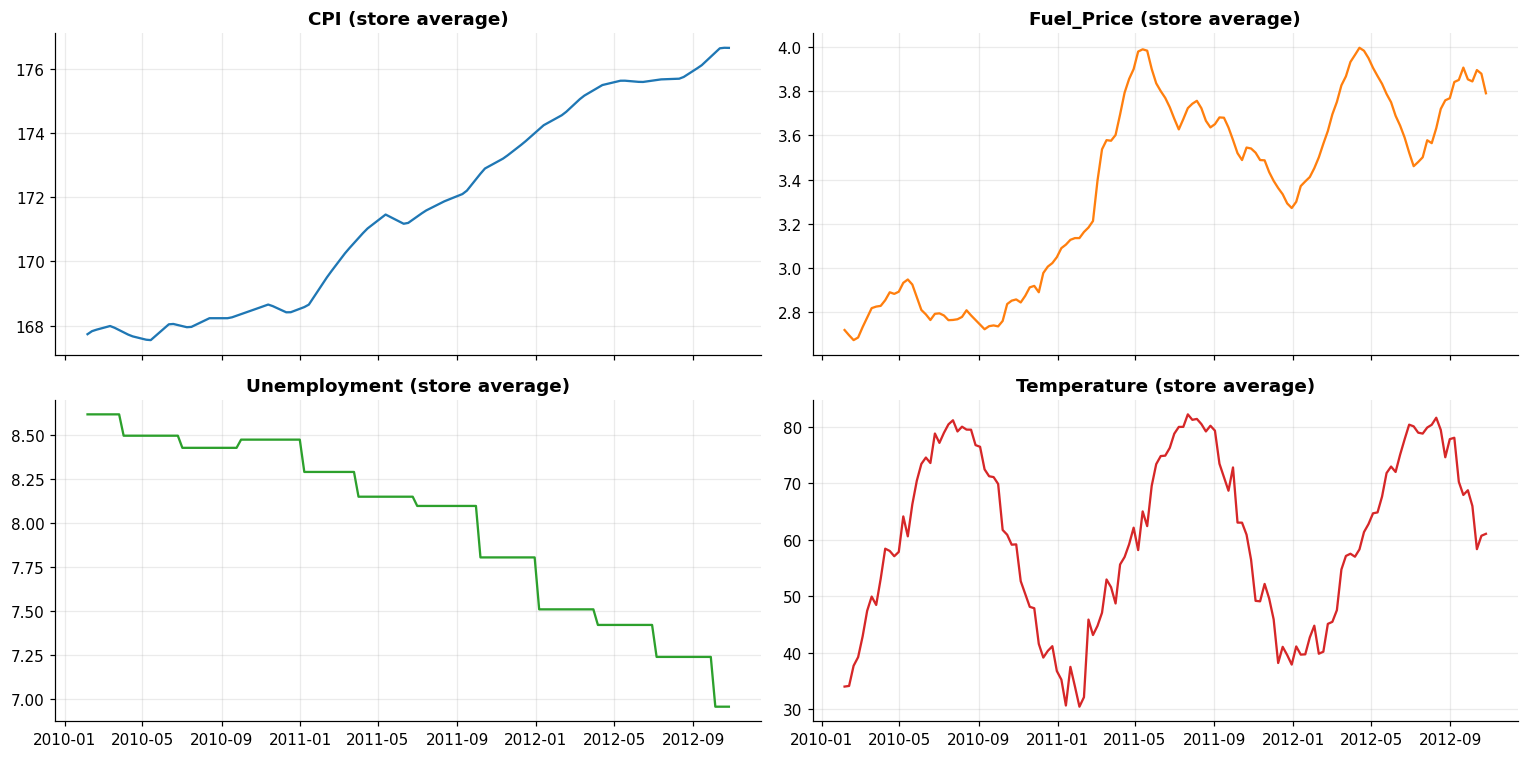

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex=True)
for ax, col, c in zip(axes.flat, ["CPI", "Fuel_Price", "Unemployment", "Temperature"], ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]):
    ax.plot(weekly.index, weekly[col], color=c); ax.set_title(f"{col} (store average)")
plt.tight_layout(); plt.show()

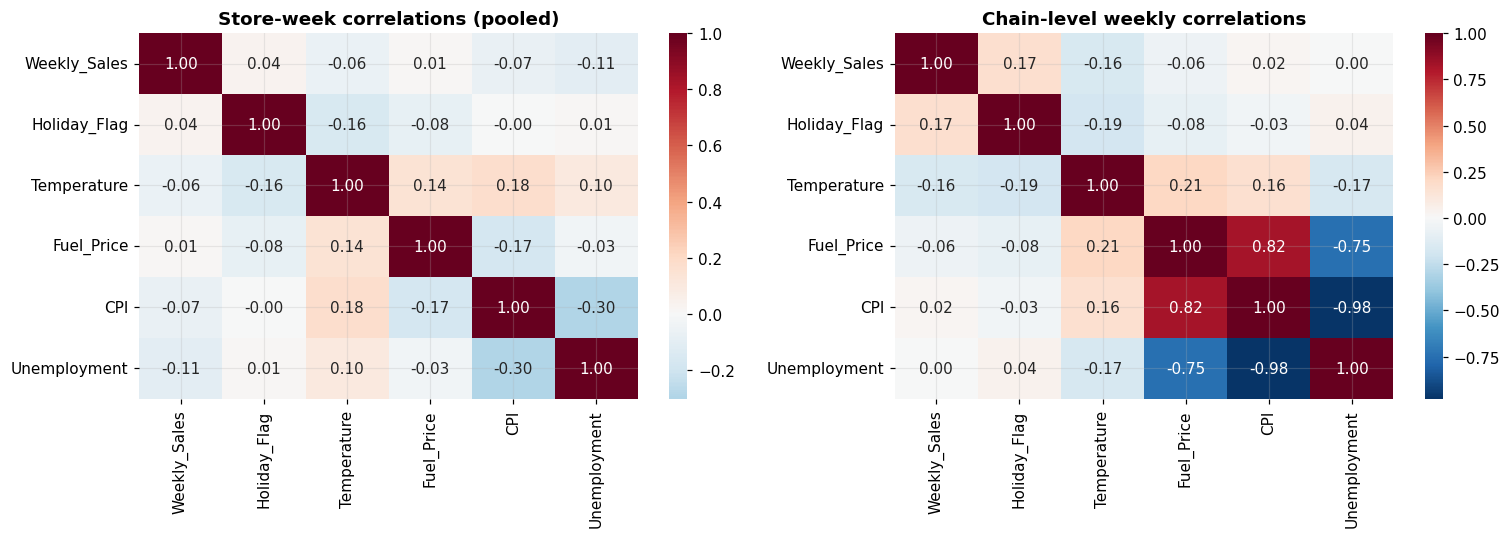

In [11]:
cols = [TARGET, "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0])
axes[0].set_title("Store-week correlations (pooled)")
sns.heatmap(weekly[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set_title("Chain-level weekly correlations")
plt.tight_layout(); plt.show()

In [12]:
# Within-store correlation removes the between-store size effect that dominates pooled correlations.
within = (
    df.groupby("Store")[cols].apply(lambda g: g.corr()[TARGET]).drop(columns=TARGET)
      .describe().loc[["mean", "25%", "50%", "75%"]]
)
display(within)

Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
mean,0.13,-0.11,-0.01,0.06,-0.06
25%,0.09,-0.26,-0.14,-0.10,-0.19
50%,0.15,-0.13,-0.00,0.08,-0.05
75%,0.19,0.04,0.12,0.24,0.08


## 4. Decomposition & stationarity

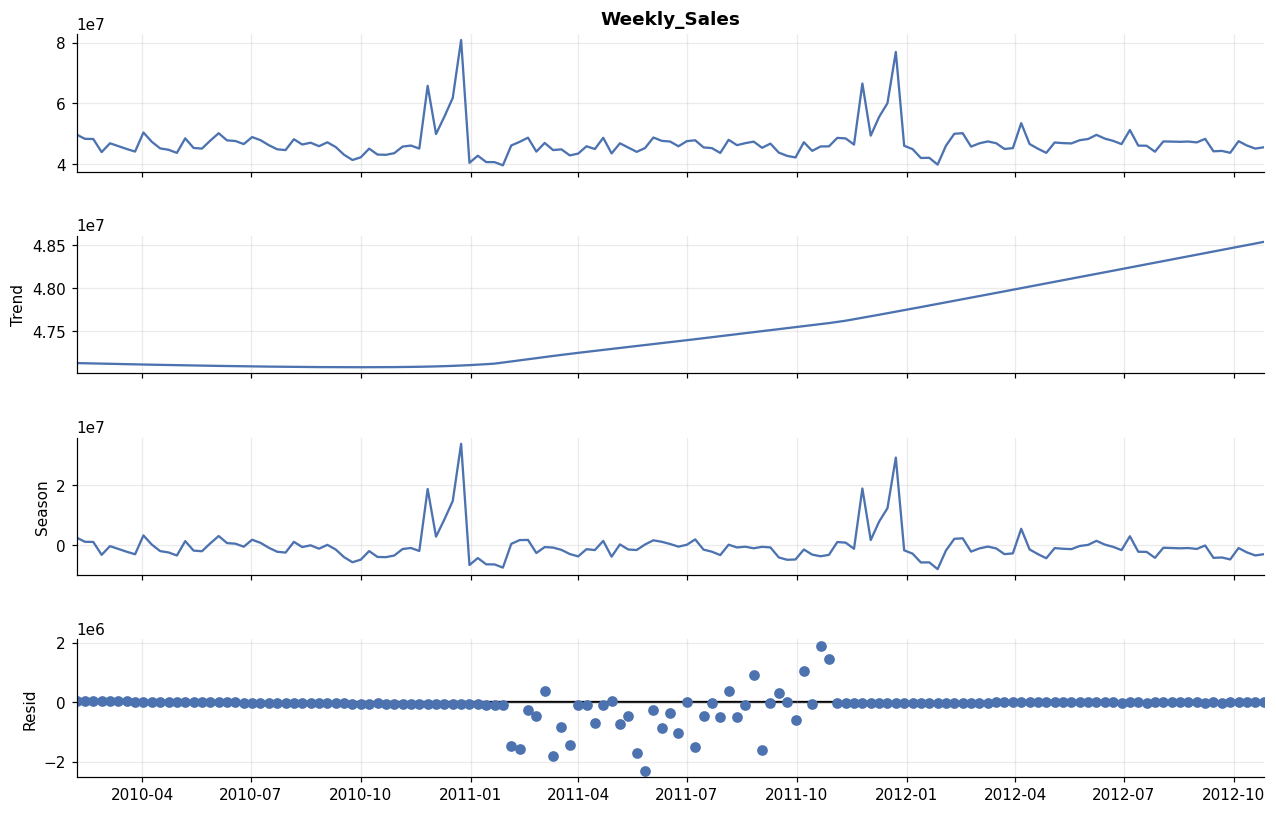

Seasonal strength: 0.99 | Trend strength: 0.54  (0 = none, 1 = maximal)


In [13]:
stl = STL(weekly[TARGET], period=52, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(13, 8); plt.show()
strength_seas = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
strength_trend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
print(f"Seasonal strength: {strength_seas:.2f} | Trend strength: {strength_trend:.2f}  (0 = none, 1 = maximal)")

In [14]:
y = data.train[TARGET]  # diagnostics on training data only
tests = {
    "Level": y,
    "1st difference": y.diff(),
    "Seasonal difference (52)": y.diff(52),
    "Seasonal + 1st difference": y.diff(52).diff(),
}
adf = pd.DataFrame({k: run_adf_test(v) for k, v in tests.items()}).T
adf["crit_5%"] = adf.critical_values.apply(lambda d: d["5%"])
display(adf[["adf_statistic", "p_value", "crit_5%", "used_lag", "n_obs", "verdict"]])

,adf_statistic,p_value,crit_5%,used_lag,n_obs,verdict
Level,-5.27,0.00,-2.89,4,109,Stationary (reject H0 at 5%; p=0.0000)
1st difference,-6.62,0.00,-2.89,5,107,Stationary (reject H0 at 5%; p=0.0000)
Seasonal difference (52),-4.83,0.00,-2.91,0,61,Stationary (reject H0 at 5%; p=0.0000)
Seasonal + 1st difference,-6.78,0.00,-2.91,2,58,Stationary (reject H0 at 5%; p=0.0000)


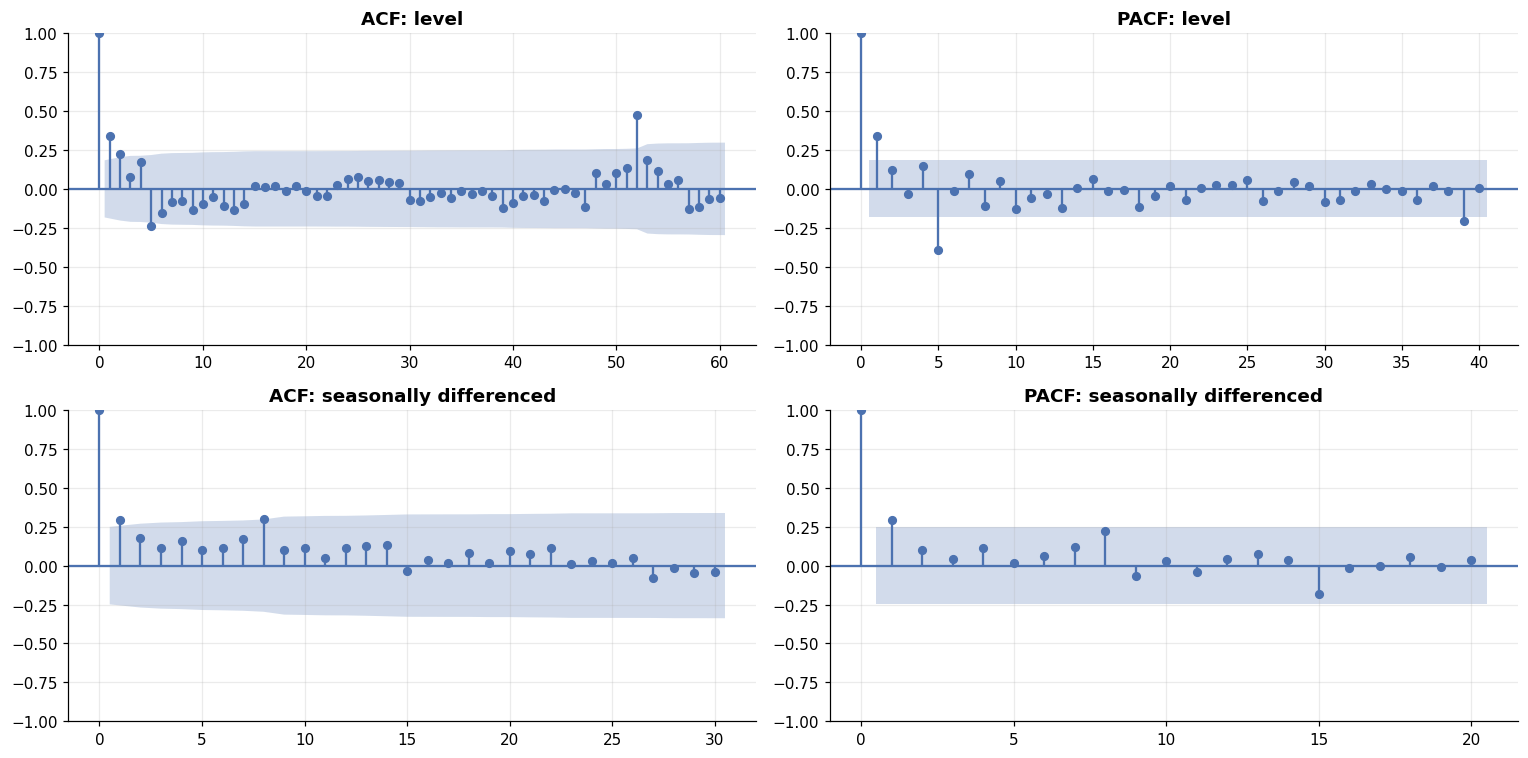

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7))
plot_acf(y, lags=60, ax=axes[0, 0], title="ACF: level")
plot_pacf(y, lags=40, ax=axes[0, 1], title="PACF: level", method="ywm")
yd = y.diff(52).dropna()
plot_acf(yd, lags=min(40, len(yd) // 2 - 1), ax=axes[1, 0], title="ACF: seasonally differenced")
plot_pacf(yd, lags=min(20, len(yd) // 2 - 1), ax=axes[1, 1], title="PACF: seasonally differenced", method="ywm")
plt.tight_layout(); plt.show()

**How to read these.** A spike near lag 52 in the level ACF shows annual seasonality, which supports a
seasonal term with `m=52`. The ADF table gives the non-seasonal differencing order `d` that
`SARIMAForecaster` picks automatically. Significant early lags in the differenced ACF/PACF point to
the MA and AR orders that `auto_arima` will search.

## 5. Feature signal for XGBoost

,corr_with_Weekly_Sales
lag_52,0.99
roll_mean_4,0.96
roll_mean_12,0.95
lag_1,0.95
lag_4,0.94


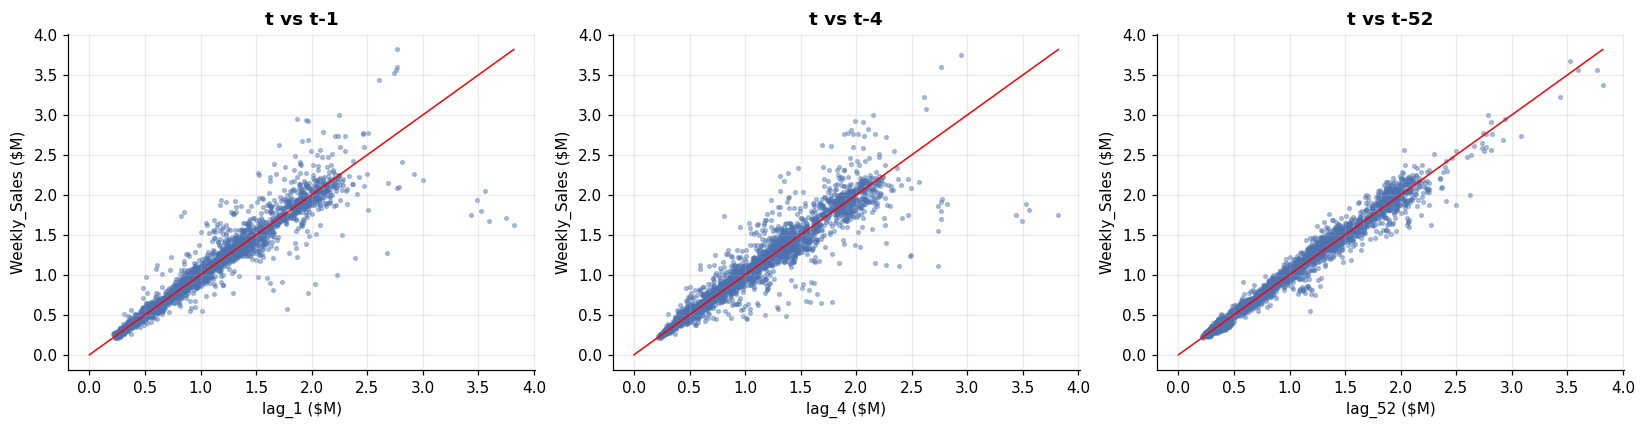

In [16]:
feats = create_features(df, group_col="Store")
lag_cols = [c for c in feats.columns if c.startswith(("lag_", "roll_mean"))]
corr = feats[[TARGET] + lag_cols].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
display(corr.to_frame("corr_with_Weekly_Sales"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axes, [1, 4, 52]):
    s = feats[[f"lag_{k}", TARGET]].dropna().sample(n=min(3000, feats[f"lag_{k}"].notna().sum()), random_state=0)
    ax.scatter(s[f"lag_{k}"] / 1e6, s[TARGET] / 1e6, s=6, alpha=0.4)
    lim = [0, s.max().max() / 1e6]; ax.plot(lim, lim, color="red", lw=1)
    ax.set_xlabel(f"lag_{k} ($M)"); ax.set_ylabel("Weekly_Sales ($M)"); ax.set_title(f"t vs t-{k}")
plt.tight_layout(); plt.show()

## 6. Takeaways for modelling

The numbers above set the modelling choices in `src/models.py`:

| Observation | Modelling choice |
|---|---|
| Strong annual cycle with year-end peaks | SARIMA seasonal period `m=52`; Prophet yearly Fourier terms; XGBoost `lag_52` |
| Holiday weeks differ by event, and the Christmas peak comes before the flagged week | Named Prophet holidays with a pre-Christmas window; `Holiday_Flag` as an exogenous regressor |
| Store scales differ a lot | Global XGBoost with `Store` as a categorical feature and per-store lags |
| ADF-determined differencing | `d` selected automatically on training data only; `D` via the OCSB test |
| Macro drivers trend and leave their training range in the test window | Linear regressors in SARIMAX/Prophet; **excluded from XGBoost**, because trees can't extrapolate |

Run `python main.py` to fit all models and write the benchmark to `outputs/metrics.json`.